# AquaTrack Utilities — Water Usage Insight
## Round 2: EDA and Feature Engineering

**Status:** Executed successfully with the supplied synthetic assessment datasets.

This notebook loads the five CSV files, audits data quality, cleans and integrates the records, creates exploratory analysis tables and charts, engineers features, flags unusual readings, and writes the results to an `outputs/` folder.

**Data required:** `meter.csv`, `connections.csv`, `billing.csv`, `weather.csv`, and `maintenance.csv` in a folder named `data/` beside this notebook. The notebook also detects the supplied assessment data folder when running in the provided environment.

**Run:** Select **Run All** in VS Code/Jupyter. Required libraries: `pandas`, `numpy`, `matplotlib`, and `seaborn`.

## 1. Run the complete Round 2 workflow

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore", category=FutureWarning)
BASE_DIR = Path.cwd().resolve()
# Support both the expected project layout (./data) and the supplied assessment data folder.
if (BASE_DIR / "data").is_dir():
    DATA_DIR = BASE_DIR / "data"
elif (BASE_DIR / "water_usage_round2").is_dir():
    DATA_DIR = BASE_DIR / "water_usage_round2"
elif Path("/mnt/data/water_usage_round2").is_dir():
    DATA_DIR = Path("/mnt/data/water_usage_round2")
else:
    raise FileNotFoundError(
        "Dataset folder not found. Place meter.csv, connections.csv, billing.csv, "
        "weather.csv and maintenance.csv inside a folder named 'data' next to this notebook."
    )
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# ----------------------------
# 1. Load all five datasets
# ----------------------------
print("\n=== 1. LOADING DATASETS ===")
meter = pd.read_csv(DATA_DIR / "meter.csv")
connections = pd.read_csv(DATA_DIR / "connections.csv")
billing = pd.read_csv(DATA_DIR / "billing.csv")
weather = pd.read_csv(DATA_DIR / "weather.csv")
maintenance = pd.read_csv(DATA_DIR / "maintenance.csv")
datasets = {
    "meter": meter,
    "connections": connections,
    "billing": billing,
    "weather": weather,
    "maintenance": maintenance,
}
for name, df in datasets.items():
    print(f"{name:14s}: {df.shape[0]:>6,} rows x {df.shape[1]} columns")
# Save a summary of structure, dtypes and sample records.
structure_rows = []
for name, df in datasets.items():
    for column in df.columns:
        structure_rows.append({
            "dataset": name,
            "column": column,
            "dtype": str(df[column].dtype),
            "missing_values": int(df[column].isna().sum()),
            "unique_values": int(df[column].nunique(dropna=True)),
        })
pd.DataFrame(structure_rows).to_csv(OUTPUT_DIR / "data_structure_summary.csv", index=False)
# ----------------------------
# 2. Initial data quality audit
# ----------------------------
print("\n=== 2. INITIAL DATA QUALITY AUDIT ===")
quality_rows = []
for name, df in datasets.items():
    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
    })
quality = pd.DataFrame(quality_rows)
print(quality.to_string(index=False))
quality.to_csv(OUTPUT_DIR / "initial_quality_audit.csv", index=False)
print("\nMeter-specific issues:")
print("  Duplicate rows:", int(meter.duplicated().sum()))
print("  Missing usage:", int(meter["usage_m3"].isna().sum()))
print("  Negative usage:", int((meter["usage_m3"] < 0).sum()))
print("  Date range:", meter["date"].min(), "to", meter["date"].max())
print("  Connection type labels:", sorted(connections["type"].dropna().astype(str).unique()))
# ----------------------------
# 3. Clean and standardize
# ----------------------------
print("\n=== 3. CLEANING DATA ===")
meter_clean = meter.copy()
connections_clean = connections.copy()
billing_clean = billing.copy()
weather_clean = weather.copy()
maintenance_clean = maintenance.copy()
# Parse dates safely.
meter_clean["date"] = pd.to_datetime(meter_clean["date"], errors="coerce")
weather_clean["date"] = pd.to_datetime(weather_clean["date"], errors="coerce")
billing_clean["billing_cycle"] = billing_clean["billing_cycle"].astype("string").str.strip()
maintenance_clean["repair_date"] = pd.to_datetime(maintenance_clean["repair_date"], errors="coerce")
# Standardize identifiers and connection type labels.
for df in [meter_clean, connections_clean, billing_clean, maintenance_clean]:
    df["connection"] = df["connection"].astype("string").str.strip().str.upper()
connections_clean["type"] = (
    connections_clean["type"].astype("string").str.strip().str.lower()
    .map({"residential": "Residential", "commercial": "Commercial"})
)
connections_clean["locality"] = connections_clean["locality"].astype("string").str.strip()
connections_clean["household_size_band"] = connections_clean["household_size_band"].astype("string").str.strip()
# Remove exact duplicate meter records before computing totals.
before_duplicates = len(meter_clean)
meter_clean = meter_clean.drop_duplicates().copy()
removed_duplicates = before_duplicates - len(meter_clean)
# Negative consumption is invalid for this analysis; convert to missing, then exclude
# these invalid readings from consumption calculations rather than treating them as real usage.
negative_mask = meter_clean["usage_m3"] < 0
negative_count = int(negative_mask.sum())
meter_clean.loc[negative_mask, "usage_m3"] = np.nan
# Missing usage cannot be reliably inferred from adjacent readings in this assessment.
# Keep a record in the audit, but exclude missing usage from analysis rows.
missing_usage_count = int(meter_clean["usage_m3"].isna().sum())
meter_clean = meter_clean.dropna(subset=["date", "connection", "usage_m3"]).copy()
# A connection/date should have at most one reading after duplicate removal.
# If any conflicting duplicate key remains, aggregate the available readings by mean
# and document this explicit rule.
conflicting_keys = int(meter_clean.duplicated(subset=["date", "connection"], keep=False).sum())
meter_clean = (
    meter_clean.groupby(["date", "connection"], as_index=False)["usage_m3"]
    .mean()
)
# Numeric validation and basic cleaning for weather and billing.
for col in ["temperature", "rain"]:
    weather_clean[col] = pd.to_numeric(weather_clean[col], errors="coerce")
weather_clean = weather_clean.dropna(subset=["date"]).drop_duplicates(subset=["date"], keep="first")
weather_clean["rain"] = weather_clean["rain"].clip(lower=0)
billing_clean["charge"] = pd.to_numeric(billing_clean["charge"], errors="coerce")
billing_clean = billing_clean.dropna(subset=["connection", "billing_cycle", "charge"])
billing_clean = billing_clean[billing_clean["charge"] >= 0]
billing_clean = billing_clean.drop_duplicates(subset=["connection", "billing_cycle"], keep="first")
# Keep unmatched maintenance rows in an exception file instead of silently discarding them.
known_ids = set(connections_clean["connection"].dropna())
unmatched_maintenance = maintenance_clean[~maintenance_clean["connection"].isin(known_ids)].copy()
matched_maintenance = maintenance_clean[maintenance_clean["connection"].isin(known_ids)].copy()
unmatched_maintenance.to_csv(OUTPUT_DIR / "unmatched_maintenance_records.csv", index=False)
# Household size is not applicable for commercial records; standardize those labels.
connections_clean.loc[connections_clean["type"] == "Commercial", "household_size_band"] = "N/A"
print(f"Exact duplicate meter rows removed: {removed_duplicates}")
print(f"Negative meter readings converted to missing then excluded: {negative_count}")
print(f"Missing usage values excluded from usage analysis: {missing_usage_count}")
print(f"Rows in unmatched maintenance exception file: {len(unmatched_maintenance)}")
print(f"Remaining meter readings after cleaning: {len(meter_clean):,}")
# Save cleaned base datasets.
meter_clean.to_csv(OUTPUT_DIR / "clean_meter.csv", index=False)
connections_clean.to_csv(OUTPUT_DIR / "clean_connections.csv", index=False)
billing_clean.to_csv(OUTPUT_DIR / "clean_billing.csv", index=False)
weather_clean.to_csv(OUTPUT_DIR / "clean_weather.csv", index=False)
matched_maintenance.to_csv(OUTPUT_DIR / "clean_maintenance.csv", index=False)
# ----------------------------
# 4. Create daily analysis table
# ----------------------------
print("\n=== 4. INTEGRATING DATA ===")
analysis = meter_clean.merge(connections_clean, on="connection", how="left", validate="many_to_one")
analysis = analysis.merge(weather_clean, on="date", how="left", validate="many_to_one")
# Add daily maintenance indicator and days since repair where repair date exists.
maintenance_features = matched_maintenance[["connection", "leak_report", "repair_date"]].copy()
maintenance_features["leak_report"] = (
    maintenance_features["leak_report"].astype("string").str.strip().str.lower()
    .map({"yes": 1, "no": 0})
)
# One record per connection for a safe many-to-one merge; use latest repair date.
maintenance_features = (
    maintenance_features.groupby("connection", as_index=False)
    .agg(leak_report=("leak_report", "max"), repair_date=("repair_date", "max"))
)
analysis = analysis.merge(maintenance_features, on="connection", how="left", validate="many_to_one")
analysis["leak_report"] = analysis["leak_report"].fillna(0).astype(int)
analysis["repair_date"] = pd.to_datetime(analysis["repair_date"], errors="coerce")
analysis["days_from_repair"] = (analysis["date"] - analysis["repair_date"]).dt.days
# Calendar features and per-connection rolling baseline for anomaly screening.
analysis["month"] = analysis["date"].dt.month
analysis["month_name"] = analysis["date"].dt.month_name()
analysis["day_of_week"] = analysis["date"].dt.day_name()
analysis["is_weekend"] = analysis["date"].dt.dayofweek >= 5
analysis["year_month"] = analysis["date"].dt.to_period("M").astype(str)
# Per-connection median and MAD-based robust spike indicator.
grouped = analysis.groupby("connection")["usage_m3"]
analysis["connection_median_usage"] = grouped.transform("median")
analysis["connection_usage_std"] = grouped.transform("std").replace(0, np.nan)
analysis["z_score"] = (
    (analysis["usage_m3"] - analysis["connection_median_usage"])
    / analysis["connection_usage_std"]
)
analysis["spike_flag"] = analysis["z_score"] >= 3
# Usage per person is approximated only for residential connections with known size band.
band_midpoint = {"1-2": 1.5, "3-4": 3.5, "5+": 5.5}
analysis["estimated_household_size"] = analysis["household_size_band"].map(band_midpoint)
analysis["usage_per_estimated_person"] = np.where(
    analysis["type"].eq("Residential") & analysis["estimated_household_size"].notna(),
    analysis["usage_m3"] / analysis["estimated_household_size"],
    np.nan
)
analysis.to_csv(OUTPUT_DIR / "analysis_daily.csv", index=False)
print("Integrated daily analysis table:", analysis.shape)
# ----------------------------
# 5. Descriptive EDA tables
# ----------------------------
print("\n=== 5. DESCRIPTIVE EDA ===")
desc = analysis["usage_m3"].describe().to_frame(name="usage_m3")
desc.to_csv(OUTPUT_DIR / "usage_descriptive_statistics.csv")
print(desc)
locality_usage = (
    analysis.groupby("locality", dropna=False)
    .agg(total_usage_m3=("usage_m3", "sum"),
         mean_daily_reading_m3=("usage_m3", "mean"),
         median_reading_m3=("usage_m3", "median"),
         readings=("usage_m3", "count"))
    .sort_values("total_usage_m3", ascending=False)
    .reset_index()
)
locality_usage.to_csv(OUTPUT_DIR / "usage_by_locality.csv", index=False)
type_usage = (
    analysis.groupby("type", dropna=False)
    .agg(total_usage_m3=("usage_m3", "sum"),
         mean_daily_reading_m3=("usage_m3", "mean"),
         median_reading_m3=("usage_m3", "median"),
         readings=("usage_m3", "count"))
    .reset_index()
)
type_usage.to_csv(OUTPUT_DIR / "usage_by_connection_type.csv", index=False)
monthly_usage = (
    analysis.groupby(["year_month", "type"], dropna=False)["usage_m3"]
    .sum().reset_index(name="total_usage_m3")
)
monthly_usage.to_csv(OUTPUT_DIR / "monthly_usage_by_type.csv", index=False)
weather_corr = analysis[["usage_m3", "temperature", "rain"]].corr(numeric_only=True)
weather_corr.to_csv(OUTPUT_DIR / "weather_usage_correlations.csv")
spikes = analysis[analysis["spike_flag"]].sort_values("z_score", ascending=False)
spikes.to_csv(OUTPUT_DIR / "detected_usage_spikes.csv", index=False)
# Before-after repair comparison: compare 30 days before and after each recorded repair.
repair_rows = []
for _, row in matched_maintenance.dropna(subset=["repair_date"]).iterrows():
    cid = row["connection"]
    repair_date = pd.Timestamp(row["repair_date"])
    subset = analysis[analysis["connection"] == cid]
    before = subset[(subset["date"] >= repair_date - pd.Timedelta(days=30)) &
                    (subset["date"] < repair_date)]["usage_m3"]
    after = subset[(subset["date"] > repair_date) &
                   (subset["date"] <= repair_date + pd.Timedelta(days=30))]["usage_m3"]
    repair_rows.append({
        "connection": cid,
        "repair_date": repair_date.date().isoformat(),
        "before_days_available": int(before.count()),
        "after_days_available": int(after.count()),
        "mean_usage_before_m3": float(before.mean()) if before.count() else np.nan,
        "mean_usage_after_m3": float(after.mean()) if after.count() else np.nan,
        "change_m3": float(after.mean() - before.mean()) if before.count() and after.count() else np.nan,
        "percent_change": float((after.mean() - before.mean()) / before.mean() * 100)
            if before.count() and after.count() and before.mean() != 0 else np.nan
    })
repair_comparison = pd.DataFrame(repair_rows)
repair_comparison.to_csv(OUTPUT_DIR / "before_after_repair.csv", index=False)
# ----------------------------
# 6. Visualizations
# ----------------------------
print("\n=== 6. CREATING VISUALIZATIONS ===")
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(data=locality_usage, x="locality", y="total_usage_m3", hue="locality", palette="deep", legend=False)
plt.title("Total Water Usage by Locality")
plt.xlabel("Locality")
plt.ylabel("Total usage (m³)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "usage_by_locality.png", dpi=160)
plt.close()
plt.figure(figsize=(8, 5))
sns.boxplot(data=analysis, x="type", y="usage_m3", hue="type", palette="deep", legend=False)
plt.title("Daily Reading Distribution by Connection Type")
plt.xlabel("Connection type")
plt.ylabel("Usage per reading (m³)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "usage_by_connection_type.png", dpi=160)
plt.close()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=analysis, x="temperature", y="usage_m3", hue="type", alpha=0.35)
plt.title("Water Usage vs Temperature")
plt.xlabel("Temperature")
plt.ylabel("Usage (m³)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "usage_vs_temperature.png", dpi=160)
plt.close()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=analysis, x="rain", y="usage_m3", hue="type", alpha=0.35)
plt.title("Water Usage vs Rainfall")
plt.xlabel("Rainfall")
plt.ylabel("Usage (m³)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "usage_vs_rainfall.png", dpi=160)
plt.close()
monthly_plot = monthly_usage.copy()
plt.figure(figsize=(11, 6))
sns.lineplot(data=monthly_plot, x="year_month", y="total_usage_m3", hue="type", marker="o")
plt.title("Monthly Water Demand by Connection Type")
plt.xlabel("Month")
plt.ylabel("Total usage (m³)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_usage_trend.png", dpi=160)
plt.close()
if not repair_comparison.empty:
    repair_plot = repair_comparison.dropna(subset=["mean_usage_before_m3", "mean_usage_after_m3"])
    if not repair_plot.empty:
        repair_long = repair_plot.melt(
            id_vars="connection",
            value_vars=["mean_usage_before_m3", "mean_usage_after_m3"],
            var_name="period", value_name="mean_usage_m3"
        )
        plt.figure(figsize=(10, 6))
        sns.barplot(data=repair_long, x="connection", y="mean_usage_m3", hue="period", palette="deep")
        plt.title("Mean Usage 30 Days Before vs After Repair")
        plt.xlabel("Connection")
        plt.ylabel("Mean usage (m³)")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "before_after_repair.png", dpi=160)
        plt.close()
# ----------------------------
# 7. Feature selection / encoding
# ----------------------------
print("\n=== 7. FEATURE ENGINEERING AND SELECTION ===")
# One-hot encode categorical variables for a prepared modeling/analysis matrix.
feature_cols = [
    "usage_m3", "temperature", "rain", "month", "is_weekend",
    "leak_report", "days_from_repair", "estimated_household_size",
    "usage_per_estimated_person", "locality", "type"
]
feature_frame = analysis[feature_cols].copy()
feature_frame = pd.get_dummies(
    feature_frame,
    columns=["locality", "type"],
    drop_first=True,
    dtype=int
)
feature_frame = feature_frame.replace([np.inf, -np.inf], np.nan)
# Save the matrix with missing feature values retained; imputation strategy can be
# selected later based on modeling needs and must be documented if a model is trained.
feature_frame.to_csv(OUTPUT_DIR / "engineered_feature_matrix.csv", index=False)
# Rank numeric features by absolute correlation with usage. This is a simple screening
# method, not proof of causation; avoid treating usage-derived columns as independent predictors.
numeric_features = analysis.select_dtypes(include=[np.number]).copy()
if "usage_m3" in numeric_features.columns:
    corr = numeric_features.corr(numeric_only=True)["usage_m3"].drop("usage_m3")
    corr_table = corr.abs().sort_values(ascending=False).rename("absolute_correlation_with_usage").to_frame()
    corr_table.to_csv(OUTPUT_DIR / "feature_correlation_screening.csv")
# ----------------------------
# 8. Final summary
# ----------------------------
print("\n=== 8. SUMMARY ===")
print("Cleaned meter readings:", f"{len(meter_clean):,}")
print("Daily analysis rows:", f"{len(analysis):,}")
print("Detected spike rows:", f"{int(analysis['spike_flag'].sum()):,}")
print("Unmatched maintenance records:", len(unmatched_maintenance))
print("\nTop localities by total usage:")
print(locality_usage.head(6).to_string(index=False))
print("\nConnection type comparison:")
print(type_usage.to_string(index=False))
print("\nWeather correlations:")
print(weather_corr.to_string())
print("\nOutputs saved in:", OUTPUT_DIR)
print("Round 2 script completed.")


=== 1. LOADING DATASETS ===
meter         : 10,793 rows x 3 columns
connections   :     60 rows x 4 columns
billing       :    360 rows x 3 columns
weather       :    181 rows x 3 columns
maintenance   :      6 rows x 4 columns

=== 2. INITIAL DATA QUALITY AUDIT ===
    dataset  rows  columns  duplicate_rows  missing_cells
      meter 10793        3              18             24
connections    60        4               0             15
    billing   360        3               0              0
    weather   181        3               0              0
maintenance     6        4               0              0

Meter-specific issues:
  Duplicate rows: 18
  Missing usage: 24
  Negative usage: 9
  Date range: 2026-01-01 to 2026-06-30
  Connection type labels: ['Commercial', 'RESIDENTIAL', 'Residential', 'commercial', 'residential']

=== 3. CLEANING DATA ===
Exact duplicate meter rows removed: 18
Negative meter readings converted to missing then excluded: 9
Missing usage values excluded fro


=== 6. CREATING VISUALIZATIONS ===



=== 7. FEATURE ENGINEERING AND SELECTION ===

=== 8. SUMMARY ===
Cleaned meter readings: 10,742
Daily analysis rows: 10,742
Detected spike rows: 36
Unmatched maintenance records: 1

Top localities by total usage:
  locality  total_usage_m3  mean_daily_reading_m3  median_reading_m3  readings
  Lakewood        5885.547               2.529242              0.857      2327
Greenfield        3879.017               1.548510              0.547      2505
   Central        3158.874               1.764734              0.826      1790
 Riverside        2179.158               0.936869              0.587      2326
  Hilltown        1051.058               1.174366              0.636       895
 Northview         382.020               0.424939              0.362       899

Connection type comparison:
       type  total_usage_m3  mean_daily_reading_m3  median_reading_m3  readings
 Commercial       10810.887               4.314001               4.46      2506
Residential        5724.787               0.

## 2. View generated charts
The workflow saves the charts as PNG files in `outputs/`. The cell below displays the charts inline.

usage_by_locality.png


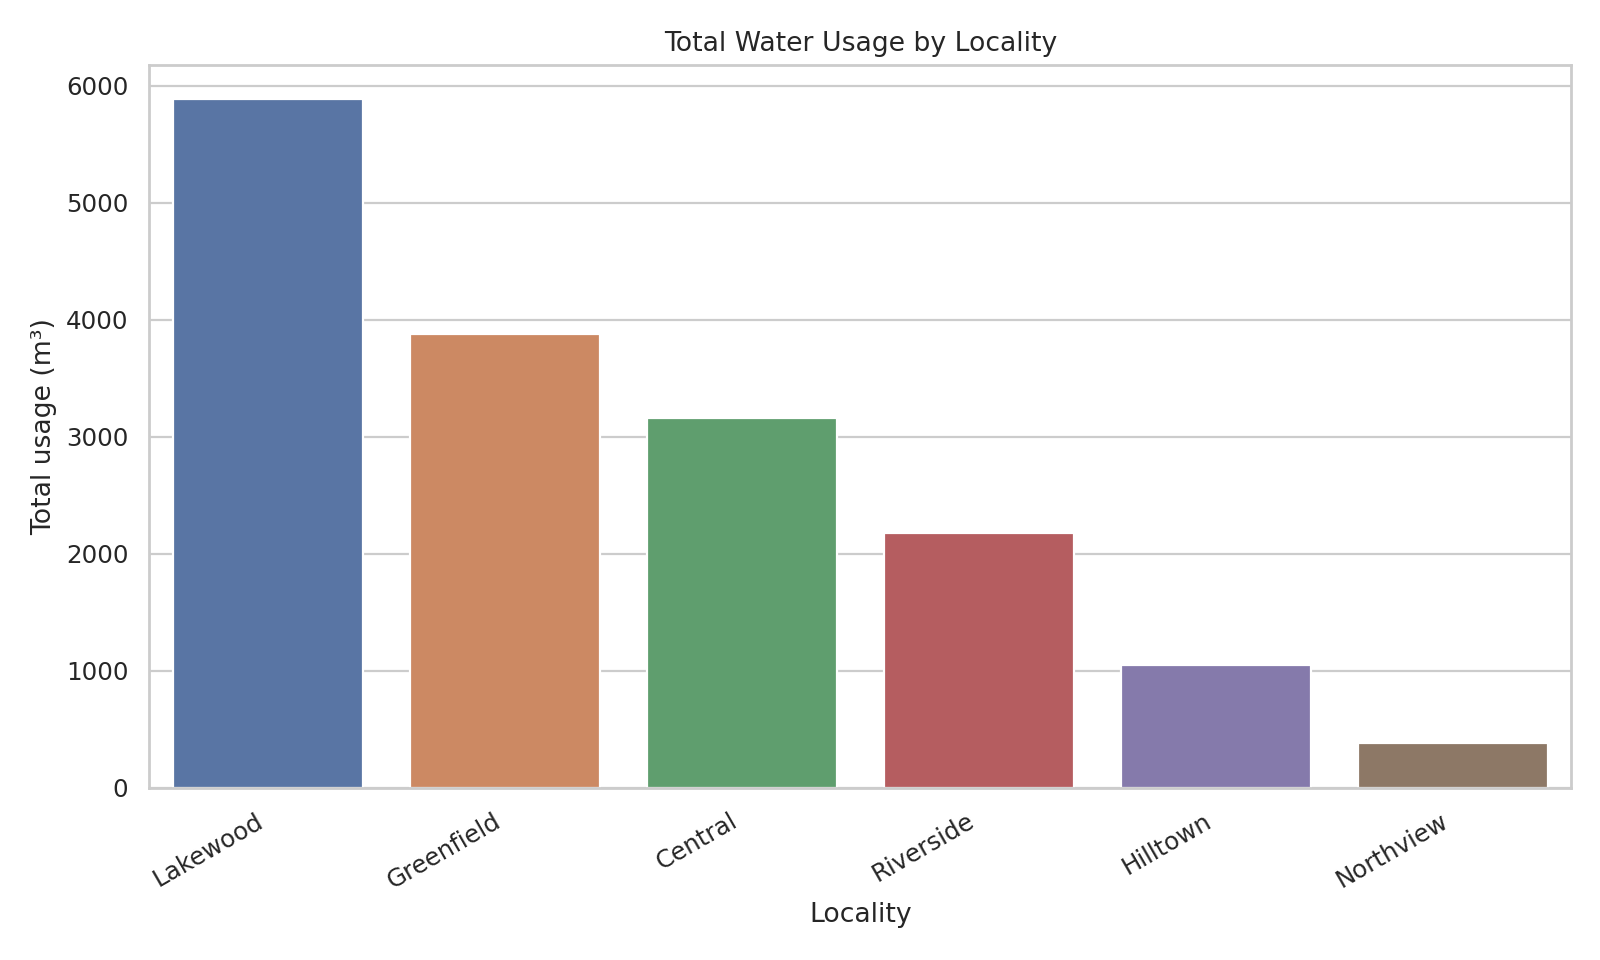

usage_by_connection_type.png


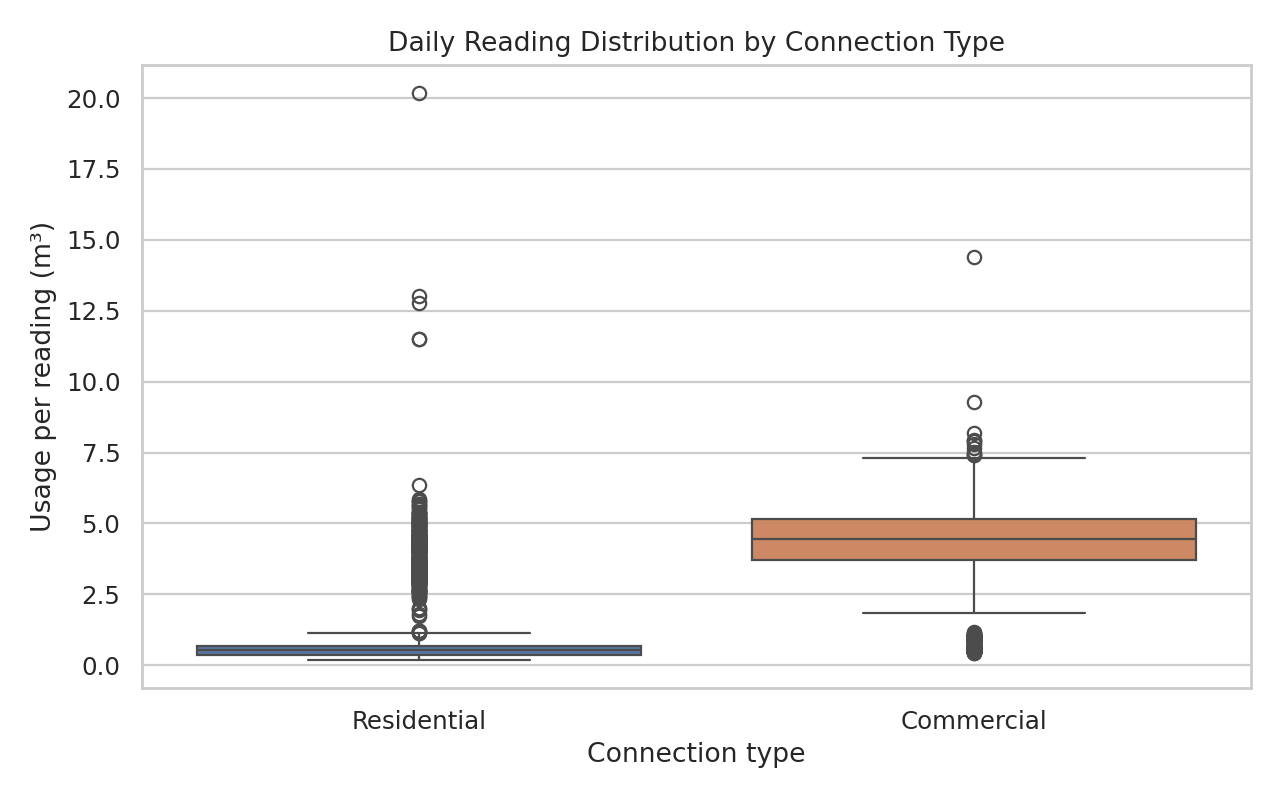

usage_vs_temperature.png


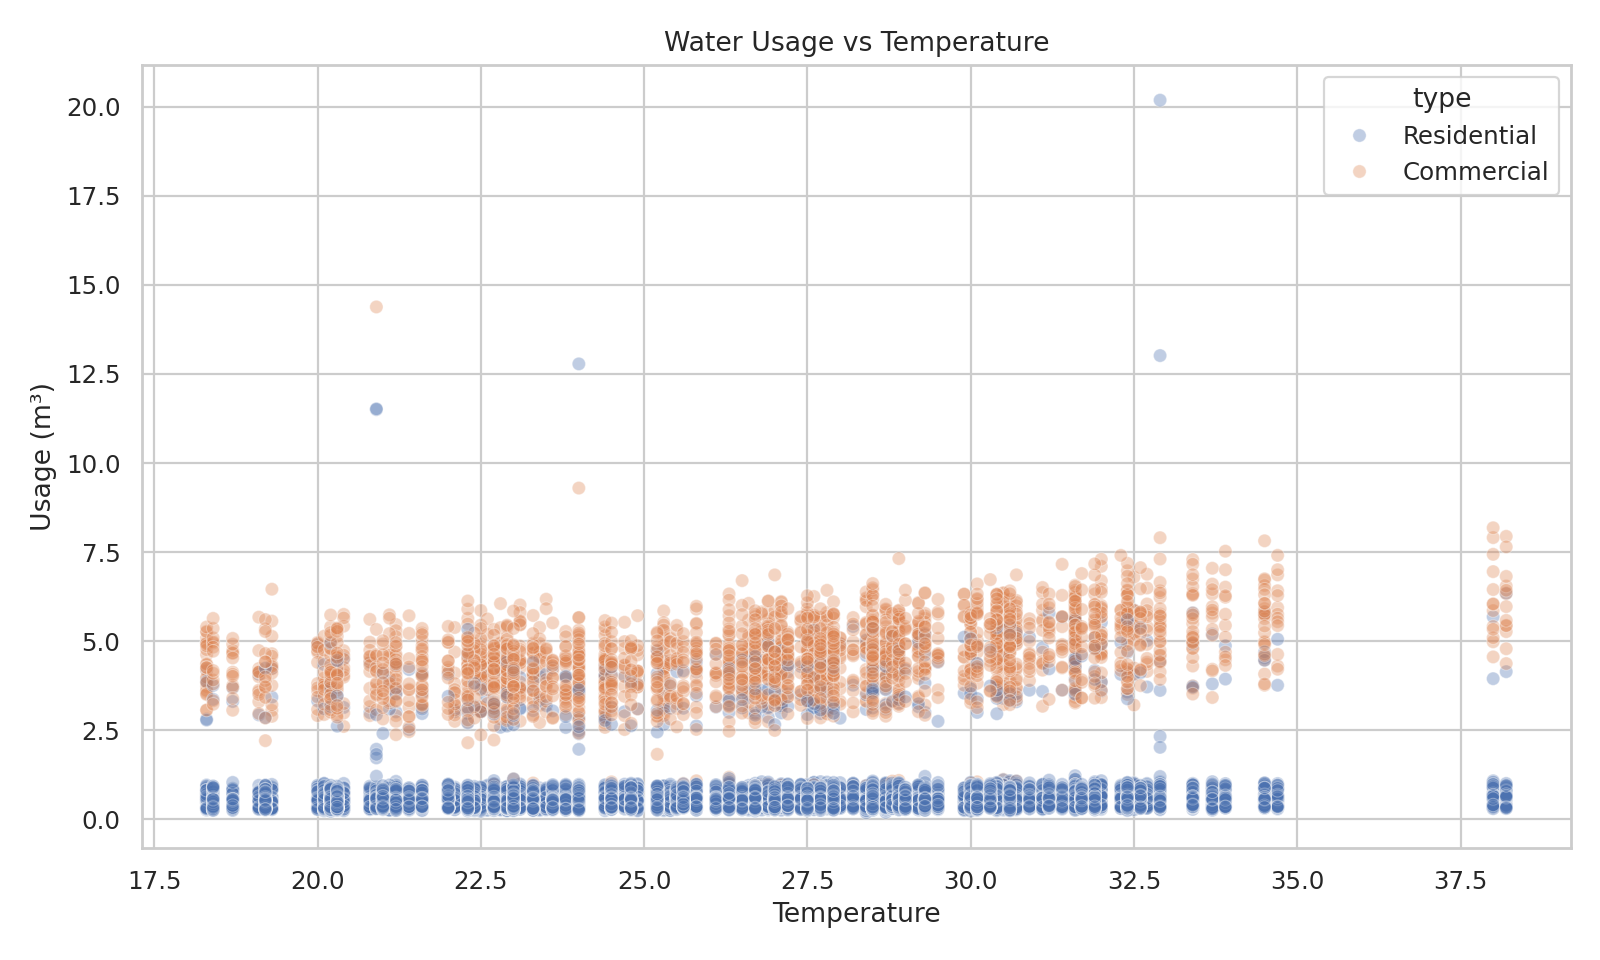

usage_vs_rainfall.png


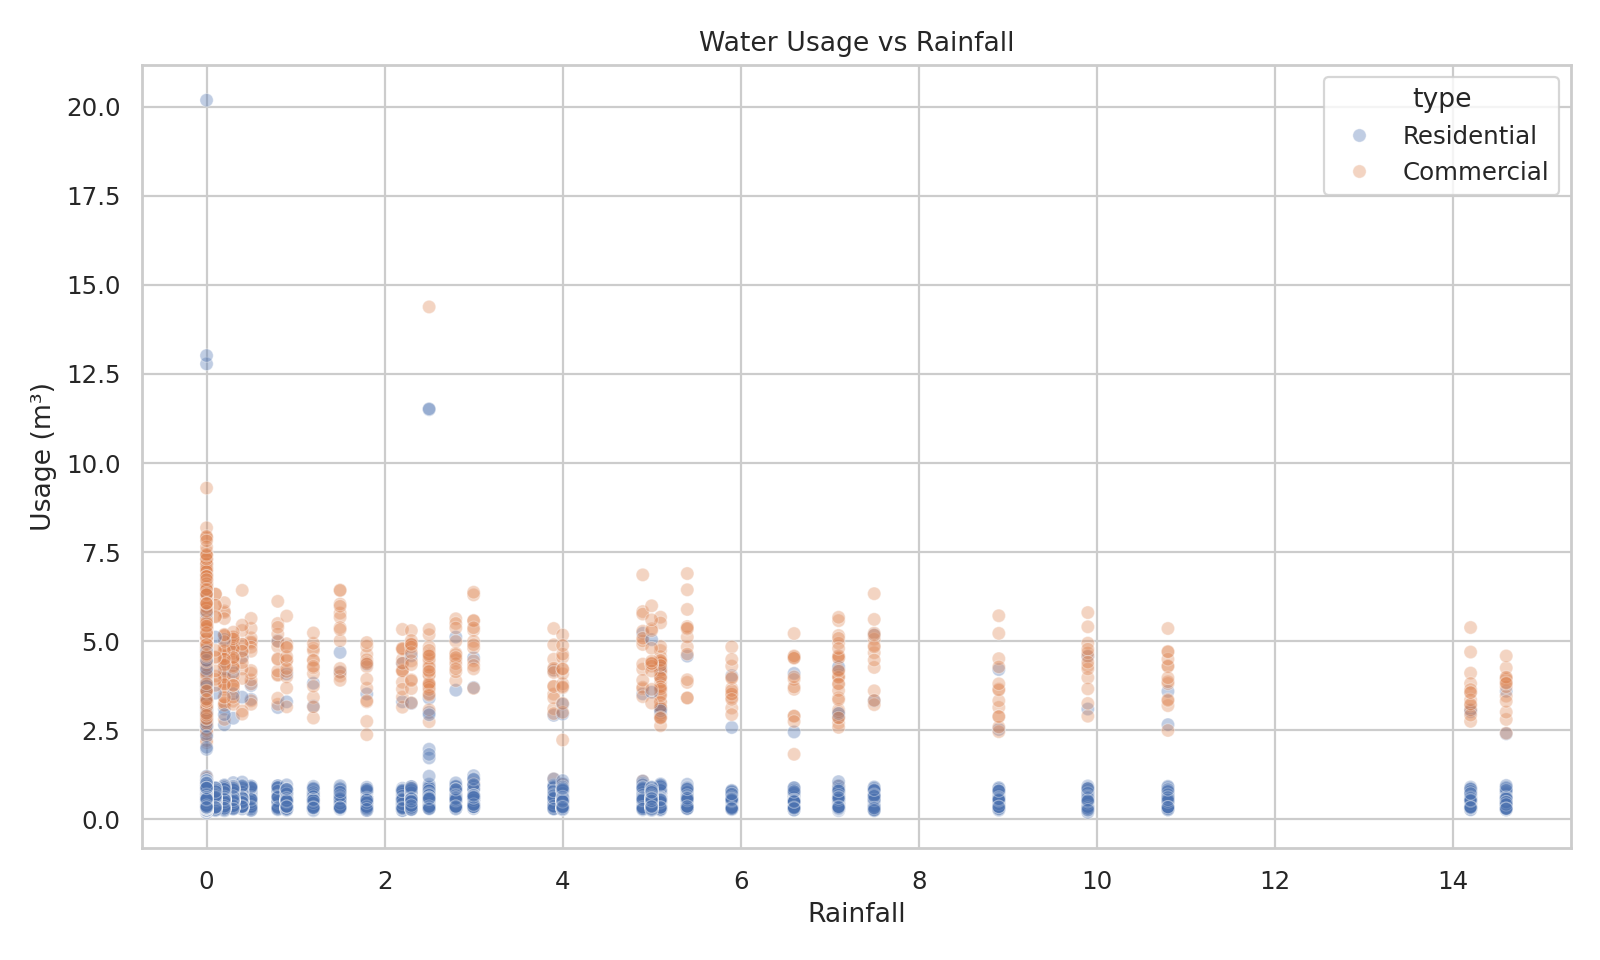

monthly_usage_trend.png


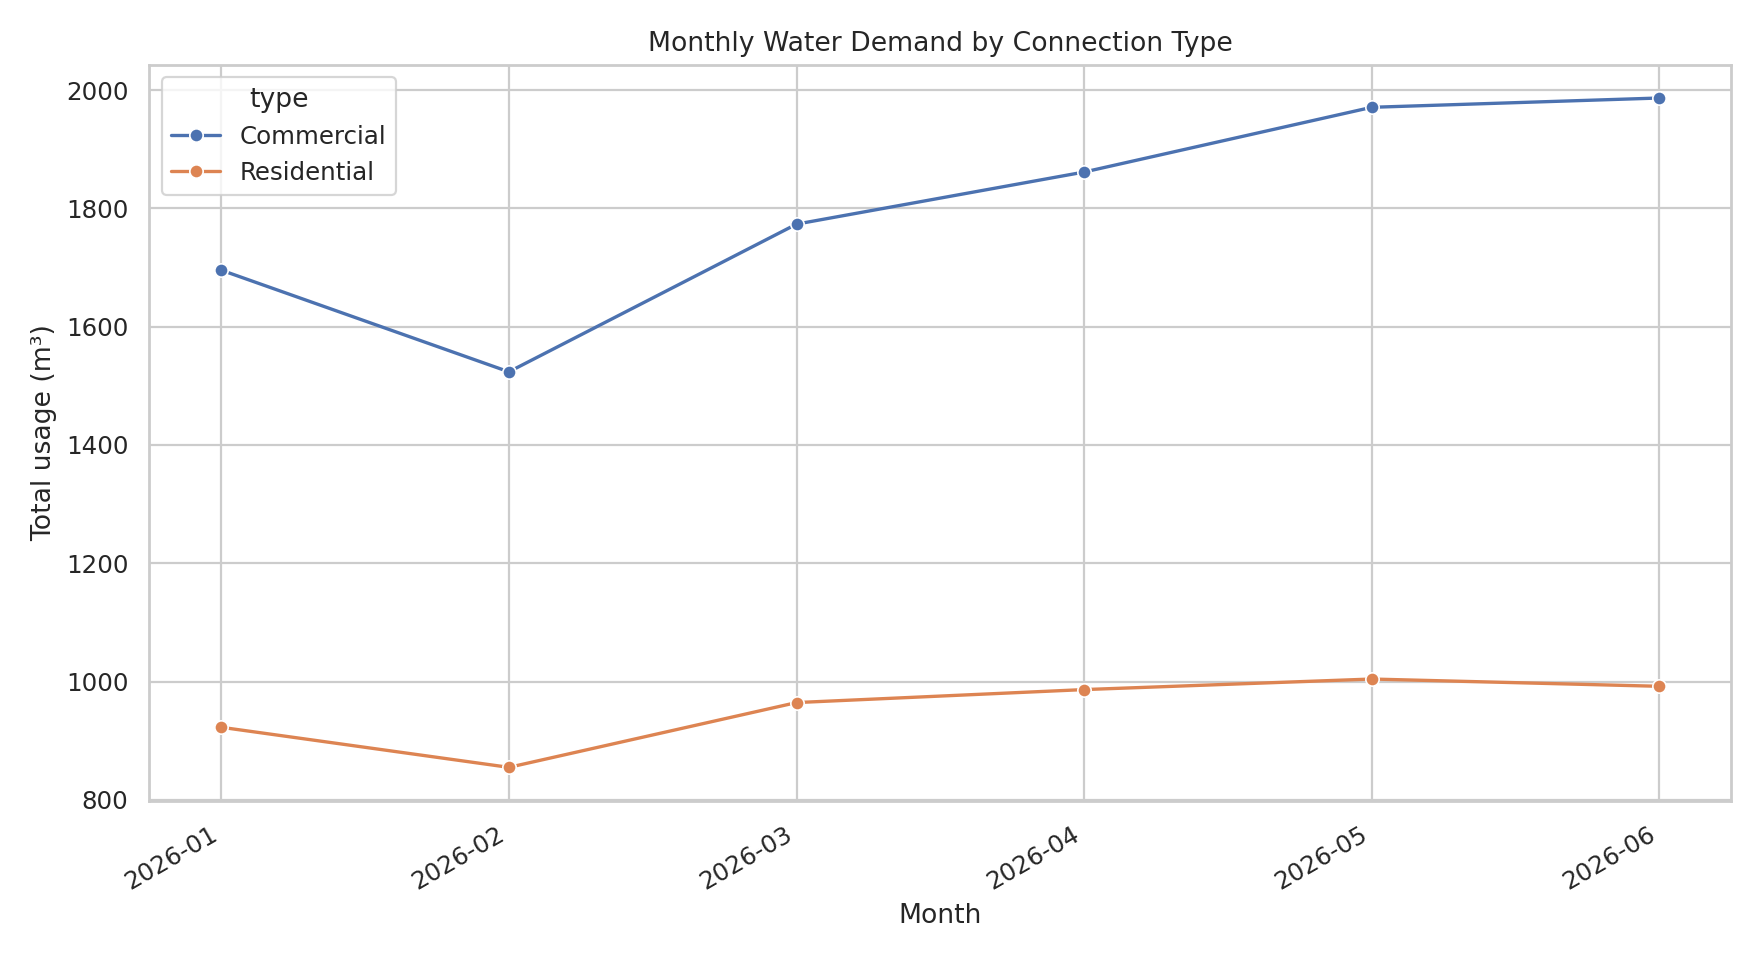

before_after_repair.png


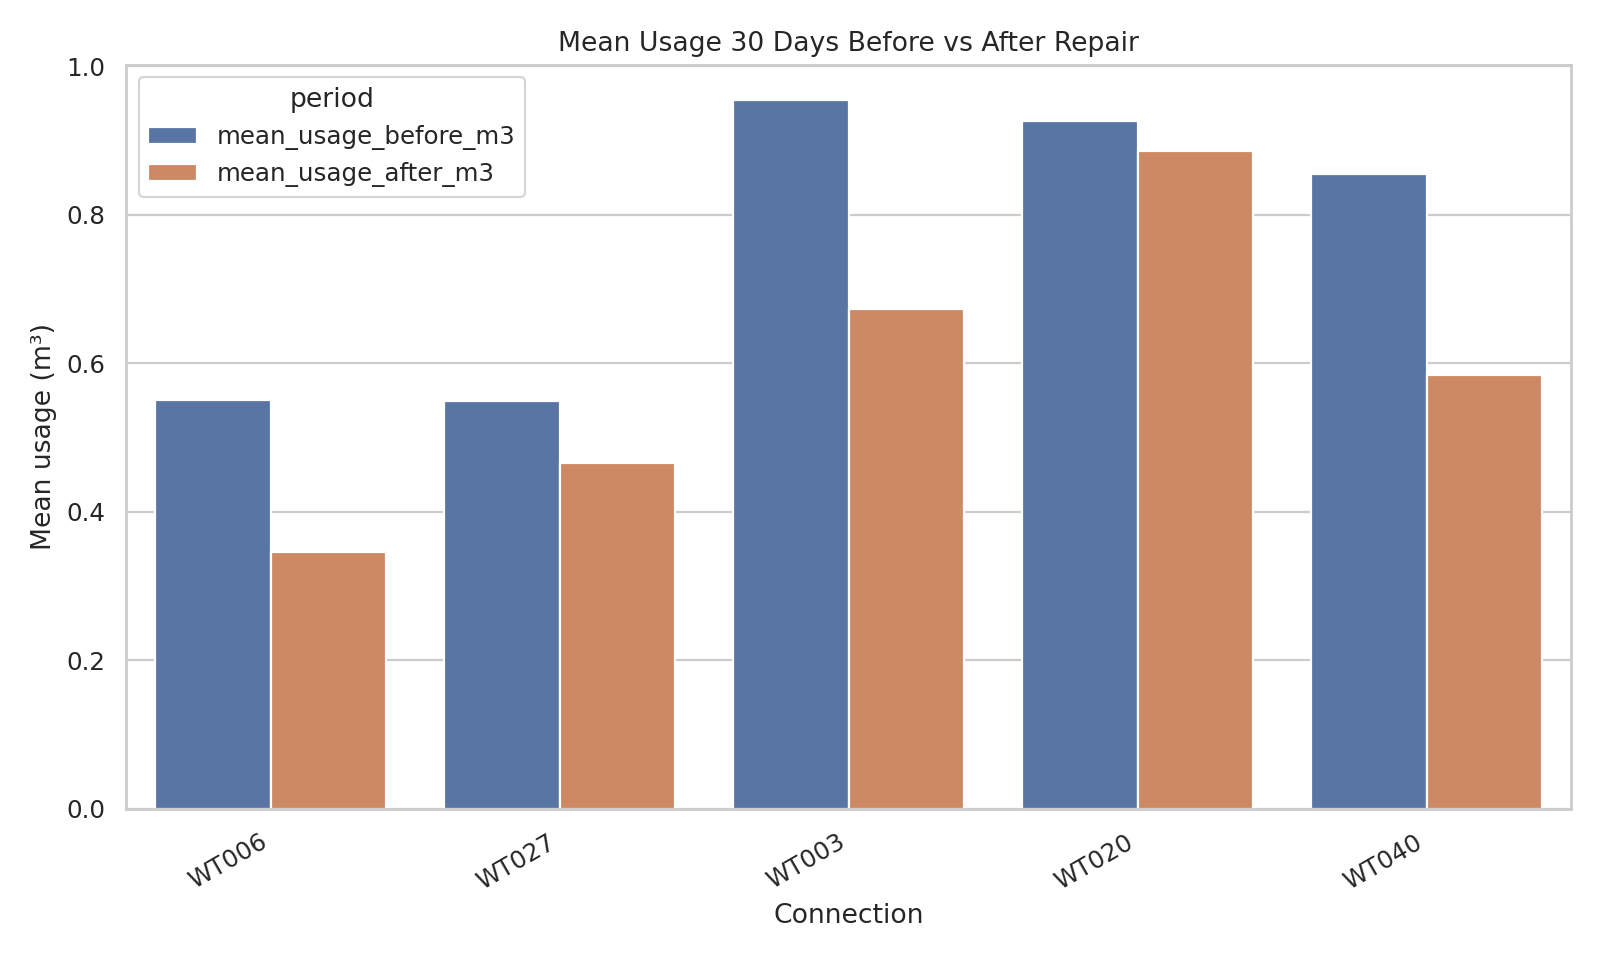

In [2]:
from IPython.display import display, Image
from pathlib import Path
chart_names = [
    "usage_by_locality.png",
    "usage_by_connection_type.png",
    "usage_vs_temperature.png",
    "usage_vs_rainfall.png",
    "monthly_usage_trend.png",
    "before_after_repair.png",
]
for chart_name in chart_names:
    chart_path = OUTPUT_DIR / chart_name
    if chart_path.exists():
        print(chart_name)
        display(Image(filename=str(chart_path)))
    else:
        print(f'Not generated for this dataset: {chart_name}')

## 3. Output files
The `outputs/` directory contains the quality audit CSVs, cleaned datasets, integrated daily analysis, descriptive statistics, locality/type summaries, monthly trends, weather correlations, detected spikes, repair comparisons, feature matrix, feature-correlation screening, and PNG charts.